<a href="https://colab.research.google.com/github/elijahschoeniger-cpu/Walmart-Project-1-/blob/main/notebooks/team_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Hurricane Analytics: Hurricane Helene, September 2024
### DS2002 Midterm Project · Team Case Crushers
**Sophie Li · Eli Schoeniger · AJ Amos**

We clean five messy Walmart data files, join them to real weather from the Open-Meteo API, and answer five questions about how Florida shoppers reacted to Hurricane Helene (landfall Sept 26, 2024). We end with a recommendation for Walmart leadership.

In [1]:
import pandas as pd, numpy as np

!git clone https://github.com/elijahschoeniger-cpu/Walmart-Project-1-.git

fatal: destination path 'Walmart-Project-1-' already exists and is not an empty directory.


### The data you are getting

Five files, in the `data/` folder next to this notebook.

| File | What it is | Size |
|---|---|---|
| `walmart_transactions.csv` | Point-of-sale records from Florida stores, September 2024 | about 25,000 rows |
| `store_locations.csv` | Store details: city, coordinates, region | about 14 rows |
| `product_catalog.csv` | The master list of products and SKUs | about 45 rows |
| `distribution_centers.csv` | Distribution center capacity and shipping cost | 5 rows |
| `inventory_and_sales.db` | SQLite database with `daily_sales_summary` and `inventory_levels` | about 7,900 rows across both tables |

Every file has quality problems, and finding them is part of the work. The brief lists what to expect:

- duplicate records
- missing values written several ways: empty, `NULL`, `N/A`, NaN
- dates and times in different formats
- the same product under several SKUs and names
- inconsistent capitalization and spacing
- category names that don't match
- numbers stored as text, and prices with `$` signs
- negative quantities
- store ids written different ways across files
- weather data in a different timezone than the sales data

You will profile the transactions file in a few minutes. The database matters mostly for Question 5.

In [2]:
import sqlite3

DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

def show_log():
    return pd.DataFrame(DECISIONS)

# Get data from repository
REPO_PATH = '/content/Walmart-Project-1-/'
catalog_data = pd.read_csv(REPO_PATH + 'data/product_catalog.csv')
distribution_center = pd.read_csv(REPO_PATH + 'data/distribution_centers.csv')
walmart_transactions = pd.read_csv(REPO_PATH + 'data/walmart_transactions.csv')
store_locations = pd.read_csv(REPO_PATH + 'data/store_locations.csv')

# Read db into pandas
conn = sqlite3.connect(REPO_PATH + 'data/inventory_and_sales.db')
cursor = conn.cursor()

print(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn))
pd.read_sql_query('PRAGMA table_info(inventory_levels)', conn)

                  name
0  daily_sales_summary
1     inventory_levels


,cid,name,type,notnull,dflt_value,pk
0,0,date,TEXT,0,None,0
1,1,store_id,TEXT,0,None,0
2,2,sku,TEXT,0,None,0
3,3,units_on_hand,INTEGER,0,None,0
4,4,units_on_order,INTEGER,0,None,0
5,5,reorder_point,INTEGER,0,None,0


Section for Cleaning (include decisions made using log)

In [3]:
import pandas as pd, os

def profile(df, name='dataset'):
    print(f'=== {name} ===')
    print(f'{len(df):,} rows x {len(df.columns)} columns')
    print()
    summary = pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'nulls': df.isnull().sum(),
        'null_pct': (100 * df.isnull().mean()).round(1),
        'distinct': df.nunique(),
    })
    print(summary)
    print()
    print('exact duplicate rows:', df.duplicated().sum())
    return summary


profile(walmart_transactions, 'walmart_transactions')
profile(store_locations, 'store_locations')



=== walmart_transactions ===
25,562 rows x 8 columns

                 dtype  nulls  null_pct  distinct
transaction_id  object      0       0.0     25532
store_id        object      0       0.0        60
timestamp       object    886       3.5     23952
sku             object      0       0.0        45
product_name    object      0       0.0        63
category        object      0       0.0        37
quantity         int64      0       0.0        11
unit_price      object      0       0.0      3668

exact duplicate rows: 30
=== store_locations ===
14 rows x 8 columns

              dtype  nulls  null_pct  distinct
store_id     object      0       0.0        14
store_name   object      0       0.0        12
city         object      0       0.0        12
state        object      0       0.0         3
zip_code      int64      0       0.0        12
latitude    float64      1       7.1        11
longitude   float64      1       7.1        11
region       object      0       0.0         7

e

,dtype,nulls,null_pct,distinct
store_id,object,0,0.0,14
store_name,object,0,0.0,12
city,object,0,0.0,12
state,object,0,0.0,3
zip_code,int64,0,0.0,12
latitude,float64,1,7.1,11
longitude,float64,1,7.1,11
region,object,0,0.0,7


SKU Consolidation

In [4]:
# Work on consolidating the SKUs!

API Call Code

In [5]:
# Connect to open-meteo
import requests

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()                       # any other bad status fails loudly
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

# A saved copy of the same Open-Meteo data (Orlando, Sept 1-30, 2024) for when you have no wifi
# or the API is down. The source column says so.
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'fallback sample',
})

try:
    weather_live = daily_weather('2024-09-01', '2024-09-30')
except requests.RequestException as err:
    print('API call failed:', err)
    weather_live = FALLBACK

same = (np.allclose(weather_live['precipitation_sum'], FALLBACK['precipitation_sum'])
        and np.allclose(weather_live['windspeed_10m_max'], FALLBACK['windspeed_10m_max']))
print('source:', weather_live['source'].iloc[0])
print('matches the saved copy:', same)
weather_live.head()

source: open-meteo
matches the saved copy: True


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.9,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,23.1,15.2,open-meteo


In [6]:
# WAITING TO MERGE WITH DATA FROM CLEANED DATABASES

Section for Showing Log

In [7]:
show_log()

""


###Charts (draft, pre-cleaning)

####Chart 1: daily orders

rows with no usable timestamp (dropped): 886


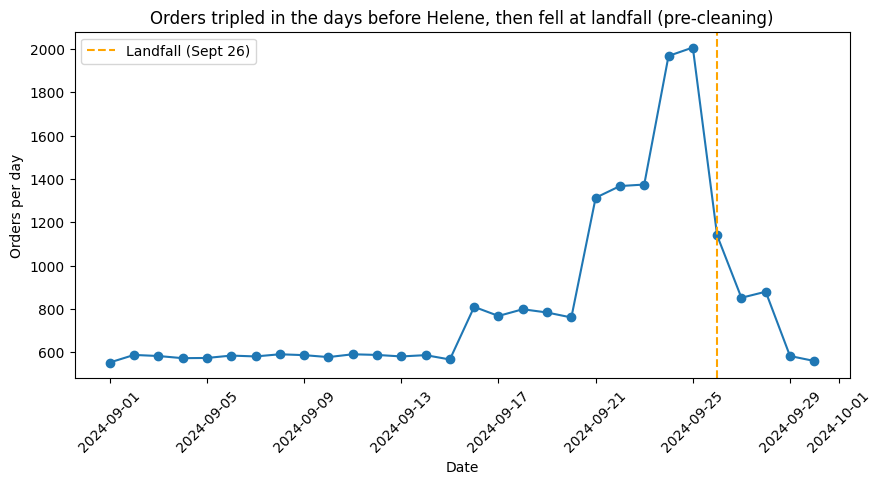

In [8]:
import matplotlib.pyplot as plt

LANDFALL = pd.Timestamp('2024-09-26')

# Work on a copy so the raw data stays untouched
tx = walmart_transactions.copy()

# Timestamps come in 3 formats; 'mixed' reads each one separately
tx['ts'] = pd.to_datetime(tx['timestamp'], format='mixed', errors='coerce')
print('rows with no usable timestamp (dropped):', tx['ts'].isna().sum())
tx = tx.dropna(subset=['ts'])

# Keep just the day, then count unique orders per day
tx['date'] = tx['ts'].dt.normalize()
daily = tx.groupby('date')['transaction_id'].nunique()

# Plot
plt.figure(figsize=(10, 4.5))
plt.plot(daily.index, daily.values, marker='o')
plt.axvline(LANDFALL, color='orange', linestyle='--', label='Landfall (Sept 26)')
plt.xlabel('Date')
plt.ylabel('Orders per day')
plt.title('Orders tripled in the days before Helene, then fell at landfall (pre-cleaning)')
plt.legend()
plt.xticks(rotation=45)
plt.show()

####Chart 2: Orders vs. Wind

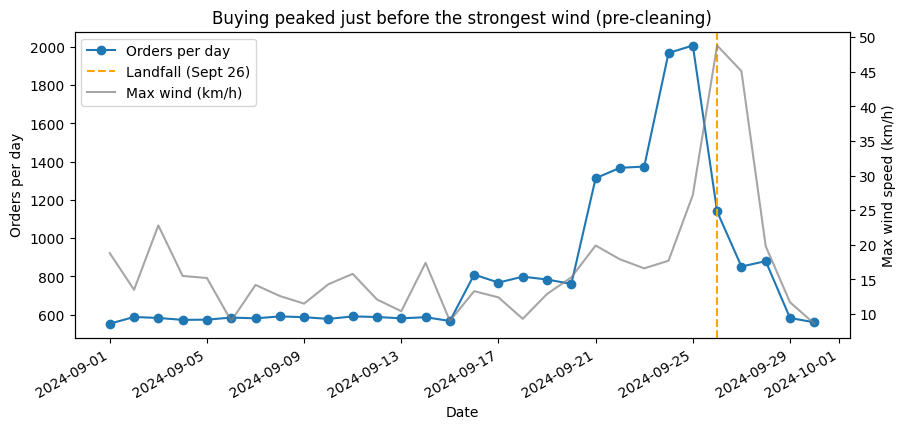

In [9]:
wind = weather_live.set_index('date')['windspeed_10m_max']

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily.index, daily.values, marker='o', label='Orders per day')
ax.axvline(LANDFALL, color='orange', linestyle='--', label='Landfall (Sept 26)')
ax.set_xlabel('Date')
ax.set_ylabel('Orders per day')

# Wind on a second y-axis, since it's in different units
ax2 = ax.twinx()
ax2.plot(wind.index, wind.values, color='gray', alpha=0.7, label='Max wind (km/h)')
ax2.set_ylabel('Max wind speed (km/h)')

# One legend for both lines
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left')

ax.set_title('Buying peaked just before the strongest wind (pre-cleaning)')
fig.autofmt_xdate()
plt.show()

####Chart 3: Top 5 Surging Categories

category
Breakfast        4.8
Emergency        3.5
Entertainment    3.2
Health           2.8
Alcohol          2.7
dtype: float64


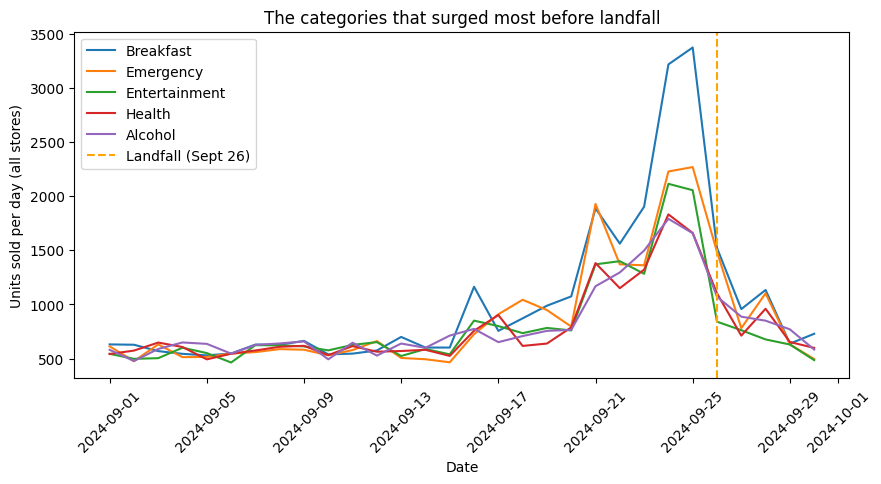

In [10]:
# Pull date, category, and units sold from the daily_sales_summary table in the database
sales_db = pd.read_sql_query('SELECT date, category, total_units FROM daily_sales_summary', conn)
sales_db['date'] = pd.to_datetime(sales_db['date'], format='mixed')   # dates come as 2024-09-12 and 20240912 - we read both

# Total units per day for each category, all stores combined
by_cat = sales_db.pivot_table(index='date', columns='category', values='total_units', aggfunc='sum')

# Derive top 5 categories by growth
growth = by_cat.loc['2024-09-23':'2024-09-25'].mean() / by_cat.loc[:'2024-09-15'].mean()
top5 = growth.sort_values(ascending=False).head(5).index
print(growth[top5].round(1))

# Plot the daily sales of top 5 categories
plt.figure(figsize=(10, 4.5))
for cat in top5:
    plt.plot(by_cat.index, by_cat[cat], label=cat)
plt.axvline(LANDFALL, color='orange', linestyle='--', label='Landfall (Sept 26)')
plt.xlabel('Date')
plt.ylabel('Units sold per day (all stores)')
plt.title('The categories that surged most before landfall')
plt.legend()
plt.xticks(rotation=45)
plt.show()